# Week 6: Radon Orientation Estimation on about 200 Cropped Images

This Week's code uses input of every vehicle cropped image out of the 5 uploaded aerial images using their annotation files, estimates each vehicle's orientation with Canny edge detection and the Radon transform (the same method as Week 5), and compares the estimates with the ground truth. It reports the error statistics like error for each vehicle type, and saves the results as CSV files.

## 1. Load Libraries

In [ ]:
import os
import glob
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from skimage.feature import canny
from skimage.transform import radon

## 2. Cut Out Every Vehicle from the Images

In [ ]:
PAD = 8
image_files = [
    "0Ago_SddH_jFbn.jpg",
    "0av2_F0GS_ESe2.jpg",
    "0B5X_l5jk_Fh2I.jpg",
    "0bGO_UHlP_zpWU.jpg",
    "0bL4_wk8I_7GPe.jpg"
]

records = []
crops = []

for image_file in image_files:
    label_file = os.path.splitext(image_file)[0] + ".txt"

    img = Image.open(image_file).convert("RGB")
    W, H = img.size

    with open(label_file) as f:
        lines = f.readlines()

    for i, line in enumerate(lines[1:], start=1):
        parts = line.split()
        if len(parts) < 11:
            continue

        coords = list(map(float, parts[0:8]))
        xs = coords[0::2]
        ys = coords[1::2]
        x_min, x_max = max(0, min(xs) - PAD), min(W, max(xs) + PAD)
        y_min, y_max = max(0, min(ys) - PAD), min(H, max(ys) + PAD)

        if x_max <= x_min or y_max <= y_min:
            continue

        crops.append(np.array(img.crop((x_min, y_min, x_max, y_max))))
        records.append({
            "Image": os.path.splitext(image_file)[0],
            "Vehicle": i,
            "Type": parts[8],
            "Ground Truth": float(parts[10])
        })

results = pd.DataFrame(records)

print("Images used:", len(image_files))
print("Vehicle crops:", len(crops))
print(results["Type"].value_counts().to_string())

Images used: 5
Vehicle crops: 240
Type
MotorCycle     114
SUV             55
AutoRicksaw     25
Sedan           16
Van              8
Tipper           5
Truck            5
PickUp           5
Tanker           2
Container        2
Bus              1
Trailer          1
Auto3WCargo      1


## 3. Convert Ground Truth to the 0-90 Degree Scale

In [ ]:
def convert_to_0_90(angle):
    angle = angle % 180
    if angle > 90:
        angle = 180 - angle
    return angle

results["Ground Truth (0-90)"] = results["Ground Truth"].apply(convert_to_0_90)

## 4. Estimate Orientation with Canny and Radon

In [ ]:
theta = np.arange(0, 180, 1)
estimates = []

for crop in crops:
    gray = cv2.cvtColor(crop, cv2.COLOR_RGB2GRAY)
    edges = canny(gray.astype(float) / 255.0, sigma=1.0)

    if not edges.any():
        estimates.append(np.nan)
        continue

    sinogram = radon(edges.astype(float), theta=theta, circle=False)
    best_projection_angle = theta[np.argmax(np.var(sinogram, axis=0))]
    radon_axis_angle = (best_projection_angle + 90) % 180
    estimates.append(convert_to_0_90(radon_axis_angle))

results["Radon Estimate"] = estimates

## 5. Error Statistics

In [ ]:
results["Radon Error"] = abs(results["Radon Estimate"] - results["Ground Truth (0-90)"])
valid = results.dropna(subset=["Radon Estimate"])

print("Crops with an estimate:", len(valid), "of", len(results))
print("Mean Absolute Error:", round(valid["Radon Error"].mean(), 2), "degrees")
print("Median Error:", round(valid["Radon Error"].median(), 2), "degrees")
print("Minimum Error:", round(valid["Radon Error"].min(), 2), "degrees")
print("Maximum Error:", round(valid["Radon Error"].max(), 2), "degrees")
print("Within 10 degrees:", round((valid["Radon Error"] <= 10).mean() * 100, 1), "%")

Crops with an estimate: 240 of 240
Mean Absolute Error: 4.79 degrees
Median Error: 2.6 degrees
Minimum Error: 0.0 degrees
Maximum Error: 80.0 degrees
Within 10 degrees: 90.8 %


## 6. Error for Each Vehicle Type

             Count   MAE  Median
Type                            
MotorCycle     114  6.18    4.42
SUV             55  3.09    2.10
AutoRicksaw     25  7.58    2.43
Sedan           16  3.47    2.60
Van              8  1.26    0.40
Truck            5  0.73    0.62
Tipper           5  0.95    0.50
PickUp           5  1.49    1.04
Container        2  0.66    0.66
Tanker           2  0.36    0.36
Auto3WCargo      1  1.60    1.60
Bus              1  1.20    1.20
Trailer          1  0.02    0.02


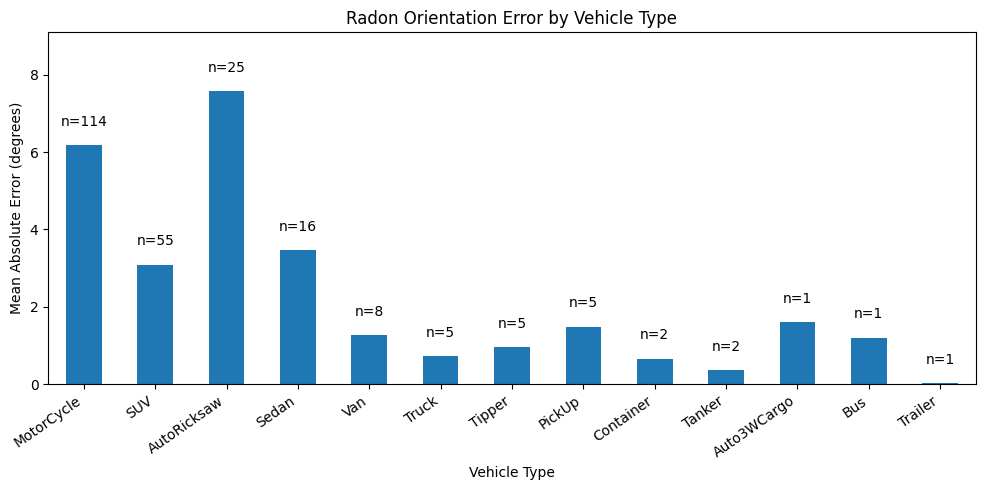

In [ ]:
by_type = valid.groupby("Type")["Radon Error"].agg(
    Count="size", MAE="mean", Median="median"
).sort_values("Count", ascending=False).round(2)

print(by_type.to_string())

ax = by_type["MAE"].plot(kind="bar", figsize=(10, 5))
for i, (n, mae) in enumerate(zip(by_type["Count"], by_type["MAE"])):
    ax.text(i, mae + 0.5, "n=" + str(n), ha="center")
plt.ylim(0, by_type["MAE"].max() * 1.2)
plt.xlabel("Vehicle Type")
plt.ylabel("Mean Absolute Error (degrees)")
plt.title("Radon Orientation Error by Vehicle Type")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

## 7. Error Distribution

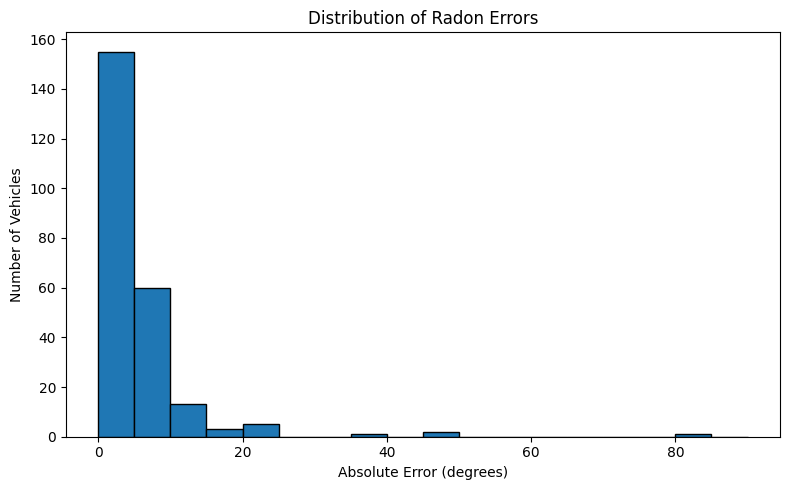

In [ ]:
plt.figure(figsize=(8, 5))

plt.hist(valid["Radon Error"], bins=18, range=(0, 90), edgecolor="black")
plt.xlabel("Absolute Error (degrees)")
plt.ylabel("Number of Vehicles")
plt.title("Distribution of Radon Errors")

plt.tight_layout()
plt.show()

## 8. Save Results to CSV

In [ ]:
results.round(2).to_csv("week6_radon_results.csv", index=False)
by_type.to_csv("week6_radon_error_by_type.csv")